In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

In [ ]:
df_source = pd.read_csv('dataset_sales_2.csv', sep=';')
df_source.head(1)

In [33]:
# Create a df_out which translates all dates by number_of_years_translation
number_of_years_translation = 5

df_out = (
    df_source
    .assign(date_order=pd.to_datetime(df_source["date_order"]) + pd.DateOffset(years=number_of_years_translation))
    .assign(date_invoice=pd.to_datetime(df_source["date_invoice"]) + pd.DateOffset(years=number_of_years_translation))
)

df_out.head()

,date_order,date_invoice,product_id,client_id,sales_net,quantity,order_channel,branch_id
0,2022-09-25,2022-09-25,2376333,188502,155.44320,3,online,2732
1,2022-09-25,2022-09-25,2520527,835089,16.39440,3,at the store,10279
2,2022-09-25,2022-09-25,2536756,1977896,365.76624,21,online,6184
3,2022-09-25,2022-09-25,3028673,598816,8.59878,201,at the store,4200
4,2022-09-25,2022-09-25,203377,2086861,1093.37400,3,by phone,7051


In [34]:
def plot_actions_per_day(df_source, column_name):
    df_dates = df_source[column_name].value_counts().reset_index()
    df_dates_cleaned = df_dates.assign(date_invoice=pd.to_datetime(df_dates[column_name])).sort_values(by=column_name, ascending=True)

    df_dates_cleaned[column_name] = pd.to_datetime(df_dates_cleaned[column_name])

    # Sort by date
    df_dates_cleaned = df_dates_cleaned.sort_values(column_name)

    fig, ax = plt.subplots(figsize=(12, 6))

    ax.bar(df_dates_cleaned[column_name], df_dates_cleaned["count"], width=1.0)

    ax.set_title("Number of orders per day")
    ax.set_xlabel("Date")
    ax.set_ylabel("Number of orders")

    # Show one tick every month
    ax.xaxis.set_major_locator(mdates.MonthLocator(interval=3))
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))

    # Optional: minor ticks every week
    # ax.xaxis.set_minor_locator(mdates.WeekdayLocator(interval=1))

    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()

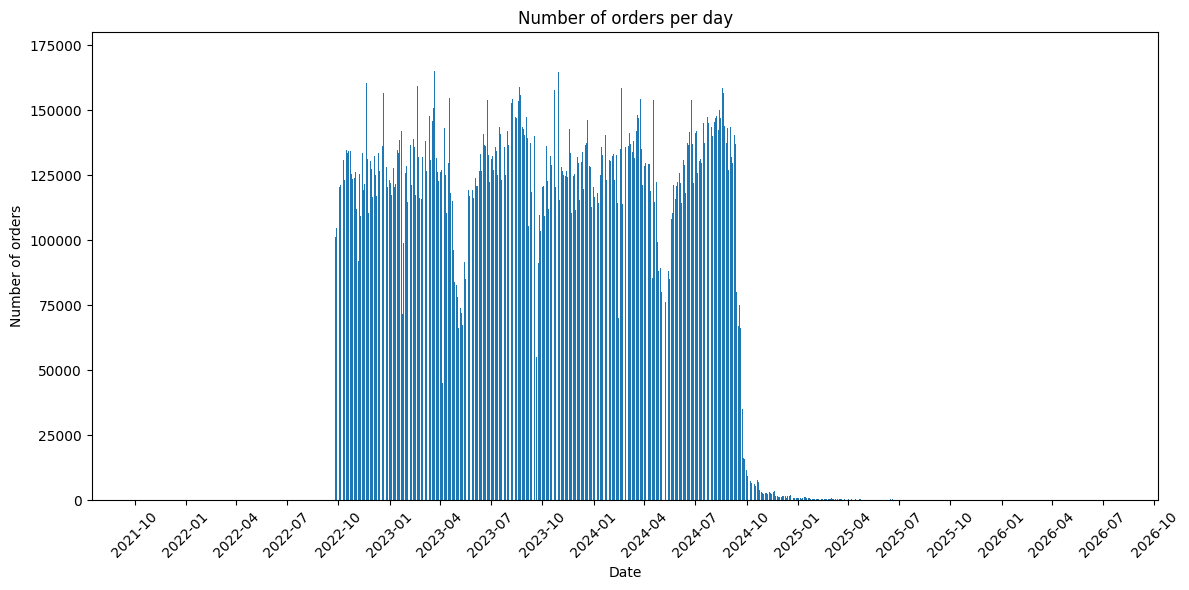

In [35]:
plot_actions_per_day(df_out, "date_invoice")

In [36]:
df_out.to_csv("dataset_sales_2026.csv", sep=";", index=False)